# California Proposition 99

Cigarette consumption, 1970–2000; first affected year 1989. Outcome: cigarette packs per capita.

The SDID reference is −15.6038278727 packs per person. This is the no-covariate example in Arkhangelsky et al. (2021), [AER](https://doi.org/10.1257/aer.20190159), using the tobacco-control setting of Abadie, Diamond and Hainmueller (2010), [JASA](https://doi.org/10.1198/jasa.2009.ap08746). The latter's covariate-based SCM specification is **not** reproduced by the outcome-only SCM row below.

Run from a checkout installed using `requirements-replication.txt` and `pip install -e .`. Full execution also needs the separately supplied local reference bundle, which is excluded from this repository. Once it is provisioned, install the original R dependencies with `python .local/reference/scripts/install_r_references.py --library .r-library` after following [the R setup guide](../docs/reference_backends.md). The notebook downloads immutable public data with **requests**, checks the reference specification, and exports five publication figures locally as PDF, SVG and 300 dpi PNG. The figures are embedded below; generated exports stay outside version control. See [the replication guide](../docs/replication.md) and [the figure guide](../docs/plotting.md).

In [1]:
%matplotlib inline
import hashlib
import os
import json
import time
from dataclasses import replace
from functools import partial
from io import BytesIO
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from pysynth import (
    SyntheticControl, SCUL, IndividualSC, TwoStageIndividualSC,
    SyntheticDID, DifferenceInDifferences, PySyncon, SCM, compare,
    plot_paths, plot_effects, plot_comparison, save_figure,
    select_estimator, donor_sensitivity, plot_backtest, plot_donor_sensitivity,
)
from pysynth.datasets import DATASETS
from pysynth.replication import (
    LITERATURE_BENCHMARKS, replicate, check_replication, reference_comparisons,
    california_paper_inference,
)
from pysynth.plotting import reference_comparison_table

pd.Series({p: version(p) for p in [
    'pysynth-control', 'numpy', 'scipy', 'pandas', 'matplotlib',
    'pysyncon', 'SyntheticControlMethods',
]}, name='version')

pysynth-control             0.1.0
numpy                       2.0.2
scipy                      1.13.1
pandas                      2.3.3
matplotlib                  3.9.4
pysyncon                    1.7.0
SyntheticControlMethods    1.1.17
Name: version, dtype: object

## Download and verify the academic data

The URL names an immutable upstream commit. SHA256 verification fails
visibly if the bytes differ. No manual download or bundled data is required.

In [2]:
name = 'california'
spec = DATASETS[name]
response = requests.get(spec.url, timeout=30)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == spec.sha256
data = pd.read_csv(BytesIO(response.content), sep=spec.separator)
panel = spec.panel(data)
print(spec.citation)
print(spec.url)
print(f'{panel.n_control} donors; {panel.n_pre} pre-periods; {panel.n_post} post-periods')
data.head()

Abadie, Diamond & Hainmueller (2010), doi:10.1198/jasa.2009.ap08746; Arkhangelsky et al. (2021), doi:10.1257/aer.20190159
https://raw.githubusercontent.com/synth-inference/synthdid/70c1ce3eac58e28c30b67435ca377bb48baa9b8a/data/california_prop99.csv
38 donors; 19 pre-periods; 12 post-periods


,State,Year,PacksPerCapita,treated
0,Alabama,1970,89.800003,0
1,Arkansas,1970,100.300003,0
2,Colorado,1970,124.800003,0
3,Connecticut,1970,120.000000,0
4,Delaware,1970,155.000000,0


## Reference specification and numerical check

This uses the historical specification above. Its numerical assertion is
separate from the new-method comparison. The path figure identifies the
reference estimator explicitly. See `pysynth.replication.replicate` for
predictor windows and optimization settings.

The warm-toned annotation gives the source-reported result at its stated
precision, with a source link and specification context. It is separate
from the numerical replication check. See the
[benchmark provenance](../docs/replication.md#literature-annotations)
for the paper/author-example distinction, compatible units, and the
German paper's 2025 erratum.

/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)
/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:176: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(


/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/replication.py:111: RuntimeWarning: SDID inference: 109 of 200 draws reached max_iter (10000) before the objective-decrease stopping rule (omega: 109, lambda: 0). Increase the resample budget explicitly with inference(max_iter=...); with estimate=..., the default budget is inherited from that fit. Inspect metadata['solver_diagnostics'] for the stopping details.
  result = SyntheticDID().inference(


,label,source_label,reference,reproduced,difference,units,difference_units,window_start,window_end,statistic,approximate,citation,source_url,context
0,SDID,Published,-15.6,-15.603828,-0.003828,packs per capita,packs per capita,1989,2000,mean_effect,False,"Arkhangelsky et al. (2021), Table 1 · 1989–2000",https://arxiv.org/pdf/1812.09970v4#page=8,No covariates. Source rounded to one decimal; ...
1,SC,Published,-19.6,-19.619663,-0.019663,packs per capita,packs per capita,1989,2000,mean_effect,False,"Arkhangelsky et al. (2021), Table 1 · 1989–2000",https://arxiv.org/pdf/1812.09970v4#page=8,Table 1 specification; source rounded to one d...
2,DID,Published,-27.3,-27.349111,-0.049111,packs per capita,packs per capita,1989,2000,mean_effect,False,"Arkhangelsky et al. (2021), Table 1 · 1989–2000",https://arxiv.org/pdf/1812.09970v4#page=8,Table 1 specification; source rounded to one d...


source                   R synthdid reference ATT (paper reports -15.6)
estimate                                                     -15.603828
reference                                                    -15.603828
absolute_tolerance                                             0.000001
SE estimate                                                    8.367993
SE reference                                                   8.367993
SE absolute tolerance                                               0.0
Name: Replication check, dtype: object

**Local figure exports** (relative to the notebook directory): `figures/california/california-reference.pdf` · `figures/california/california-reference.svg` · `figures/california/california-reference.png`

**Literature source:** [Arkhangelsky et al. (2021), Table 1 · 1989–2000](https://arxiv.org/pdf/1812.09970v4#page=8)

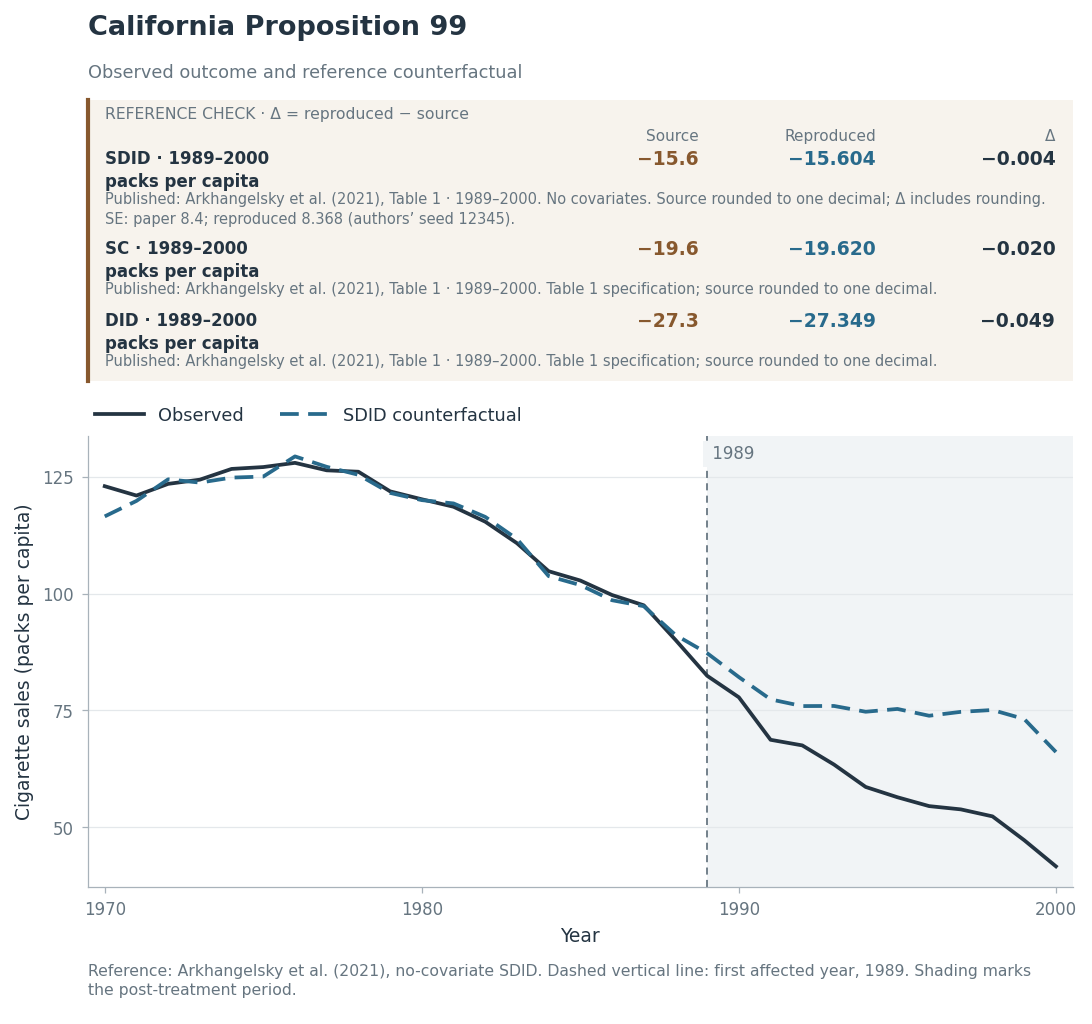

In [3]:
figure_details = {'case': 'California Proposition 99', 'outcome': 'Cigarette sales (packs per capita)', 'effect': 'Effect on cigarette sales (packs per capita)', 'units': 'packs per capita', 'periods': '1970–1988 pretreatment · 1989–2000 post-treatment · 38 donors', 'onset': '1989', 'reference': 'SDID counterfactual', 'reference_note': 'Reference: Arkhangelsky et al. (2021), no-covariate SDID. Dashed vertical line: first affected year, 1989. Shading marks the post-treatment period.'}
benchmark = LITERATURE_BENCHMARKS[name]
# Works when the kernel starts in either the repository or notebook folder.
example_dir = Path.cwd() if Path.cwd().name == 'empirical_examples' else Path.cwd() / 'empirical_examples'
figure_dir = Path(os.environ.get('PYSYNTH_FIGURE_DIR', example_dir / 'figures')) / name
figure_dir.mkdir(parents=True, exist_ok=True)

def export_figure(fig, kind):
    paths = save_figure(fig, figure_dir / f'{name}-{kind}')
    paths_text = ' · '.join(
        f'`{os.path.relpath(p, example_dir)}`' for p in paths
    )
    display(Markdown('**Local figure exports** (relative to the notebook directory): ' + paths_text))
    display(Markdown(f'**Literature source:** [{benchmark.citation}]({benchmark.source_url})'))
    return paths

reference = replicate(name, data)
report = check_replication(name, reference)
additional = None
paper_uncertainty = None
if name == 'california':
    additional = {'SC': SyntheticDID().fit_sc(panel), 'DID': DifferenceInDifferences().fit(panel)}
    paper_uncertainty = california_paper_inference(panel, reference)
    se_reference = paper_uncertainty.metadata['paper_replication']['reference_standard_error']
    np.testing.assert_allclose(paper_uncertainty.standard_error, se_reference, atol=1e-9, rtol=0)
    assert abs(additional['SC'].att - (-19.6)) <= 0.05
    assert abs(additional['DID'].att - (-27.3)) <= 0.05
    report.update({'SE estimate': paper_uncertainty.standard_error,
                   'SE reference': se_reference, 'SE absolute tolerance': 1e-9})

def matched_references(fit, additional=None):
    refs = reference_comparisons(name, fit, additional=additional)
    if paper_uncertainty is not None:
        refs = [replace(r, context=r.context + (
            f' SE: paper 8.4; reproduced {paper_uncertainty.standard_error:.3f} '
            '(authors’ seed 12345).'
        )) if r.label == 'SDID' else r for r in refs]
    return refs

references = matched_references(reference, additional=additional)
reference_table = reference_comparison_table(references)
display(reference_table)
reference_table.to_csv(figure_dir / f'{name}-references.csv', index=False)
display(pd.Series(report, name='Replication check'))
ax = plot_paths(
    reference,
    title=figure_details['case'],
    subtitle='Observed outcome and reference counterfactual',
    ylabel=figure_details['outcome'], xlabel='Year',
    observed_label='Observed',
    counterfactual_label=figure_details['reference'],
    intervention_label=figure_details['onset'],
    references=references,
    note=figure_details['reference_note'],
)
reference_files = export_figure(ax.figure, 'reference')
plt.show()

## Fit all applicable methods on a common sample

Every comparison uses the same outcome panel, eligible donors and treatment
date. Classical pysyncon SCM estimates predictor importance by nested
optimization. SyntheticControlMethods uses **all pretreatment outcome
lags and all ten optimization starts**, with checked numerical recovery
when a gradient line search fails. Neither adapter truncates the fit
to accelerate this example. Native outcome SCM is retained as the
explicitly named equal-period baseline.

SCUL calls the pinned original R functions and glmnet, selecting
`lambda.median` from fold-specific paths. Its original near-zero-variance
screening checks the full series and each training window, so data
admissibility can depend on post-period values; lasso fitting and
penalty selection use only pretreatment outcomes. Rolling windows
are stated in code. Basque has only ten pretreatment observations, so
its validation horizon must be shorter than its 28-period post window.
Penalized and robust SCM retain the explicit illustrative tuning values
shown below; these are new applications, not paper-specific calibrations.

ISC calls **MSCMT**, using the costofcare bootstrap workflow with **50
donor resamples**. 2SISC follows Petrillo et al. (2025): raw nearest-neighbor
screening followed by nested SCM on temporal predictor means, without
donor resampling. `n_neighbors=10` counts ten donors; the authors' KDTree
implementation counts the treated case in its query size. The earlier
MSCMT/50-draw two-stage variant remains explicitly available through
`backend='mscmt', n_bootstrap=50`. These aggregate panels
do not provide the survey-specific demographic predictors, eligibility
rules, or individual sampling design of the original ISC studies.

SDID uses donor post-period outcomes to estimate time weights; robust
SCM uses them for donor denoising. Neither fits to treated post-outcomes.
Each model runs in full; failures stop execution. Elapsed fitting times
and optimizer diagnostics are exported alongside the estimates.

In [4]:
scul_windows = {'california': (5, 12), 'basque': (3, 5),
                'germany': (14, 14), 'kansas': (16, 16)}
initial, horizon = scul_windows[name]
models = {
    'Outcome SCM': SyntheticControl(),
    'SCUL': SCUL(initial_window=initial, horizon=horizon),
    'ISC (full donor pool)': IndividualSC(),
    '2SISC (nearest 10)': TwoStageIndividualSC(n_neighbors=10),
    'Synthetic DID': SyntheticDID(),
    'DID': DifferenceInDifferences(),
    'pysyncon SCM': PySyncon('synth'),
    'Augmented SCM': PySyncon('augsynth'),
    'Penalized SCM (0.01)': PySyncon('pensynth', options={'lambda_': 0.01}),
    'Robust SCM (rank 3, ridge 0.1)': PySyncon('robust', options={'lambda_': 0.1, 'sv_count': 3}),
    'SyntheticControlMethods SCM': SCM('synth'),
    'Differenced SCM': SCM('diffsynth'),
}
results, elapsed = {}, {}
for label, model in models.items():
    started = time.perf_counter()
    results[label] = model.fit(panel)
    elapsed[label] = time.perf_counter() - started
    print(f'{label}: {elapsed[label]:.2f} seconds')
comparison = compare(results)
comparison['elapsed_seconds'] = pd.Series(elapsed)
if name == 'california':
    references = matched_references(results['Synthetic DID'], additional={
        'SC': additional['SC'], 'DID': results['DID'],
    })
elif name == 'kansas':
    references = matched_references(results['Augmented SCM'])
diagnostics = {label: fit.metadata for label, fit in results.items()}
(figure_dir / f'{name}-diagnostics.json').write_text(
    json.dumps(diagnostics, indent=2, default=str) + chr(10)
)
display_labels = {
    'ISC (full donor pool)': 'ISC · full donor pool',
    '2SISC (nearest 10)': '2SISC · nearest 10',
    'pysyncon SCM': 'SCM · pysyncon',
    'Penalized SCM (0.01)': 'Penalized SCM · λ = 0.01',
    'Robust SCM (rank 3, ridge 0.1)': 'Robust SCM · rank 3',
    'SyntheticControlMethods SCM': 'SCM · SCMethods',
    'Differenced SCM': 'Differenced SCM',
}
comparison.round(4)

Outcome SCM: 0.02 seconds


SCUL: 0.54 seconds


ISC (full donor pool): 0.60 seconds
2SISC (nearest 10): 0.02 seconds
Synthetic DID: 0.12 seconds
DID: 0.00 seconds


/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)


pysyncon SCM: 15.15 seconds


Augmented SCM: 0.57 seconds
Penalized SCM (0.01): 0.13 seconds
Robust SCM (rank 3, ridge 0.1): 0.00 seconds


SyntheticControlMethods SCM: 0.23 seconds


Differenced SCM: 11.37 seconds


,att,pre_rmse,donors_used,weight_sum,elapsed_seconds
model,,,,,
Outcome SCM,-19.5137,1.6564,6,1.0000,0.0158
SCUL,-25.8787,2.4034,5,0.6134,0.5418
ISC (full donor pool),-20.2526,2.0726,17,1.0000,0.5996
2SISC (nearest 10),-27.7267,6.4991,10,1.0000,0.0229
Synthetic DID,-15.6038,1.8057,28,1.0000,0.1159
DID,-27.3491,7.1572,38,1.0000,0.0001
pysyncon SCM,-19.3706,1.6584,6,1.0000,15.1456
Augmented SCM,-15.9526,0.7337,38,1.0000,0.5707
Penalized SCM (0.01),-22.2775,3.0084,5,1.0000,0.1324


## Average effects and pretreatment fit

The left panel reports the average post-treatment gap (ATT); the right
reports pretreatment root mean squared error in the same outcome units.
Methods retain the same order in every figure. They are not ranked by
estimated effect or fit. Each dot is a point estimate: **there are no
estimated confidence intervals in these figures**. Better pretreatment
fit alone does not establish causal credibility.

The reference strip pairs each source result with its matched reproduction
and signed difference, using the same statistic and evaluation window.
Approximate paper headlines and numerical upstream examples are labelled
separately. They are not targets for every estimator.

**Local figure exports** (relative to the notebook directory): `figures/california/california-comparison.pdf` · `figures/california/california-comparison.svg` · `figures/california/california-comparison.png`

**Literature source:** [Arkhangelsky et al. (2021), Table 1 · 1989–2000](https://arxiv.org/pdf/1812.09970v4#page=8)

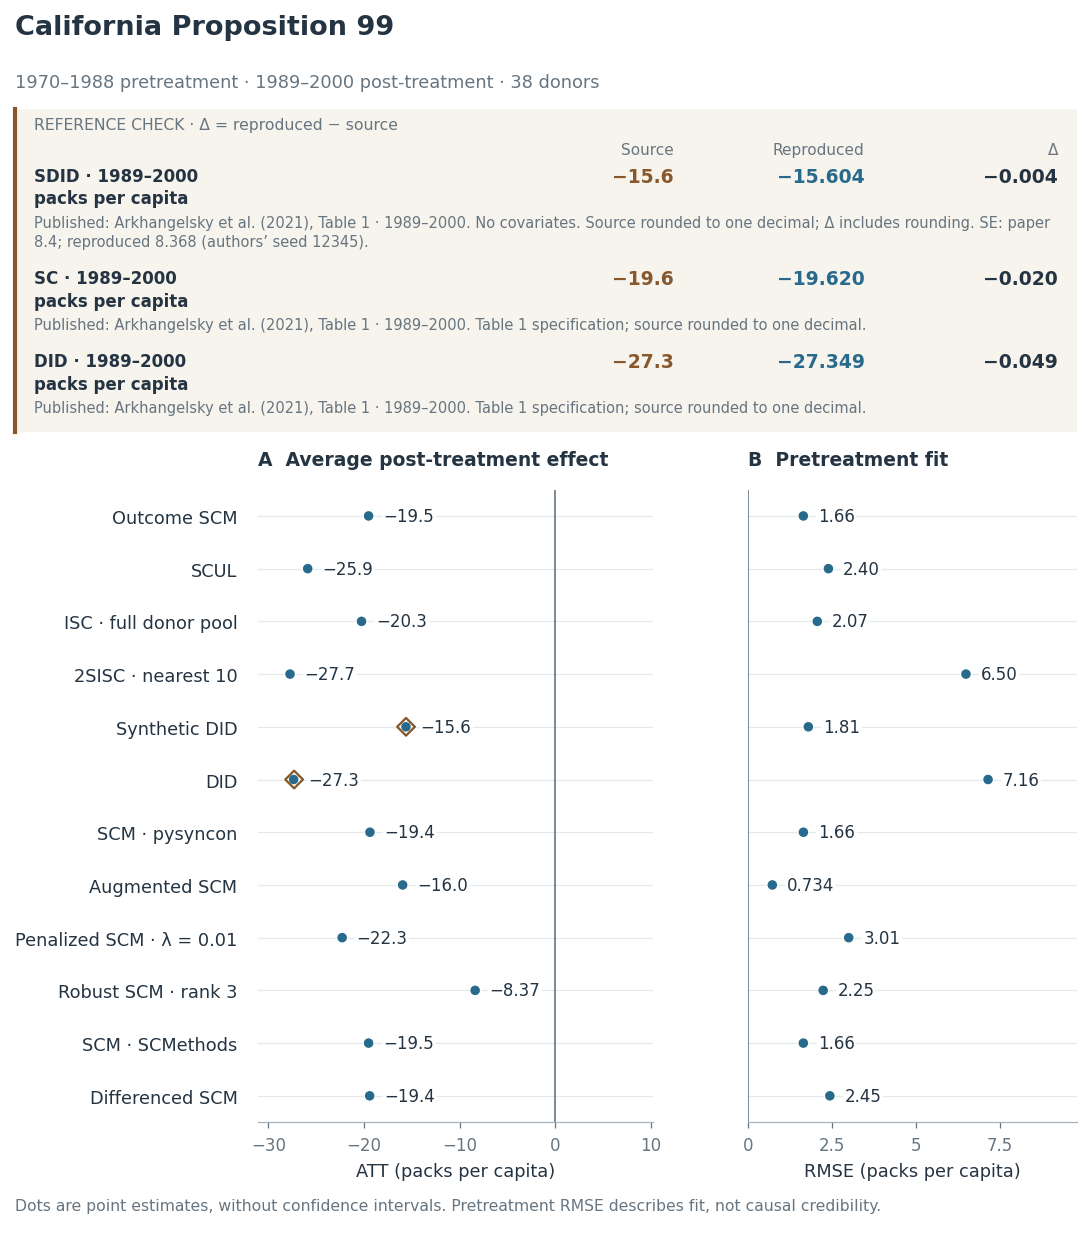

In [5]:
fig, axes = plot_comparison(
    results, labels=display_labels,
    title=figure_details['case'],
    subtitle=figure_details['periods'],
    units=figure_details['units'],
    references=references,
)
comparison_files = export_figure(fig, 'comparison')
comparison.to_csv(figure_dir / f'{name}-estimates.csv', float_format='%.12g')
plt.show()

## Effect paths on a common scale

Every panel shows **observed minus counterfactual**. All twelve panels
share the same horizontal and vertical scales; no extreme estimate is
clipped. The zero line denotes no estimated effect. The dashed vertical
line and shaded region identify the common treatment onset and post-period.
Shading does not represent uncertainty. Calendar spacing is preserved,
including quarterly observations. Panel labels replace repeated legends.
The source/reproduction strip uses matched specifications and windows.
Any numeric reference guide applies only to its matched estimator.

**Local figure exports** (relative to the notebook directory): `figures/california/california-effects.pdf` · `figures/california/california-effects.svg` · `figures/california/california-effects.png`

**Literature source:** [Arkhangelsky et al. (2021), Table 1 · 1989–2000](https://arxiv.org/pdf/1812.09970v4#page=8)

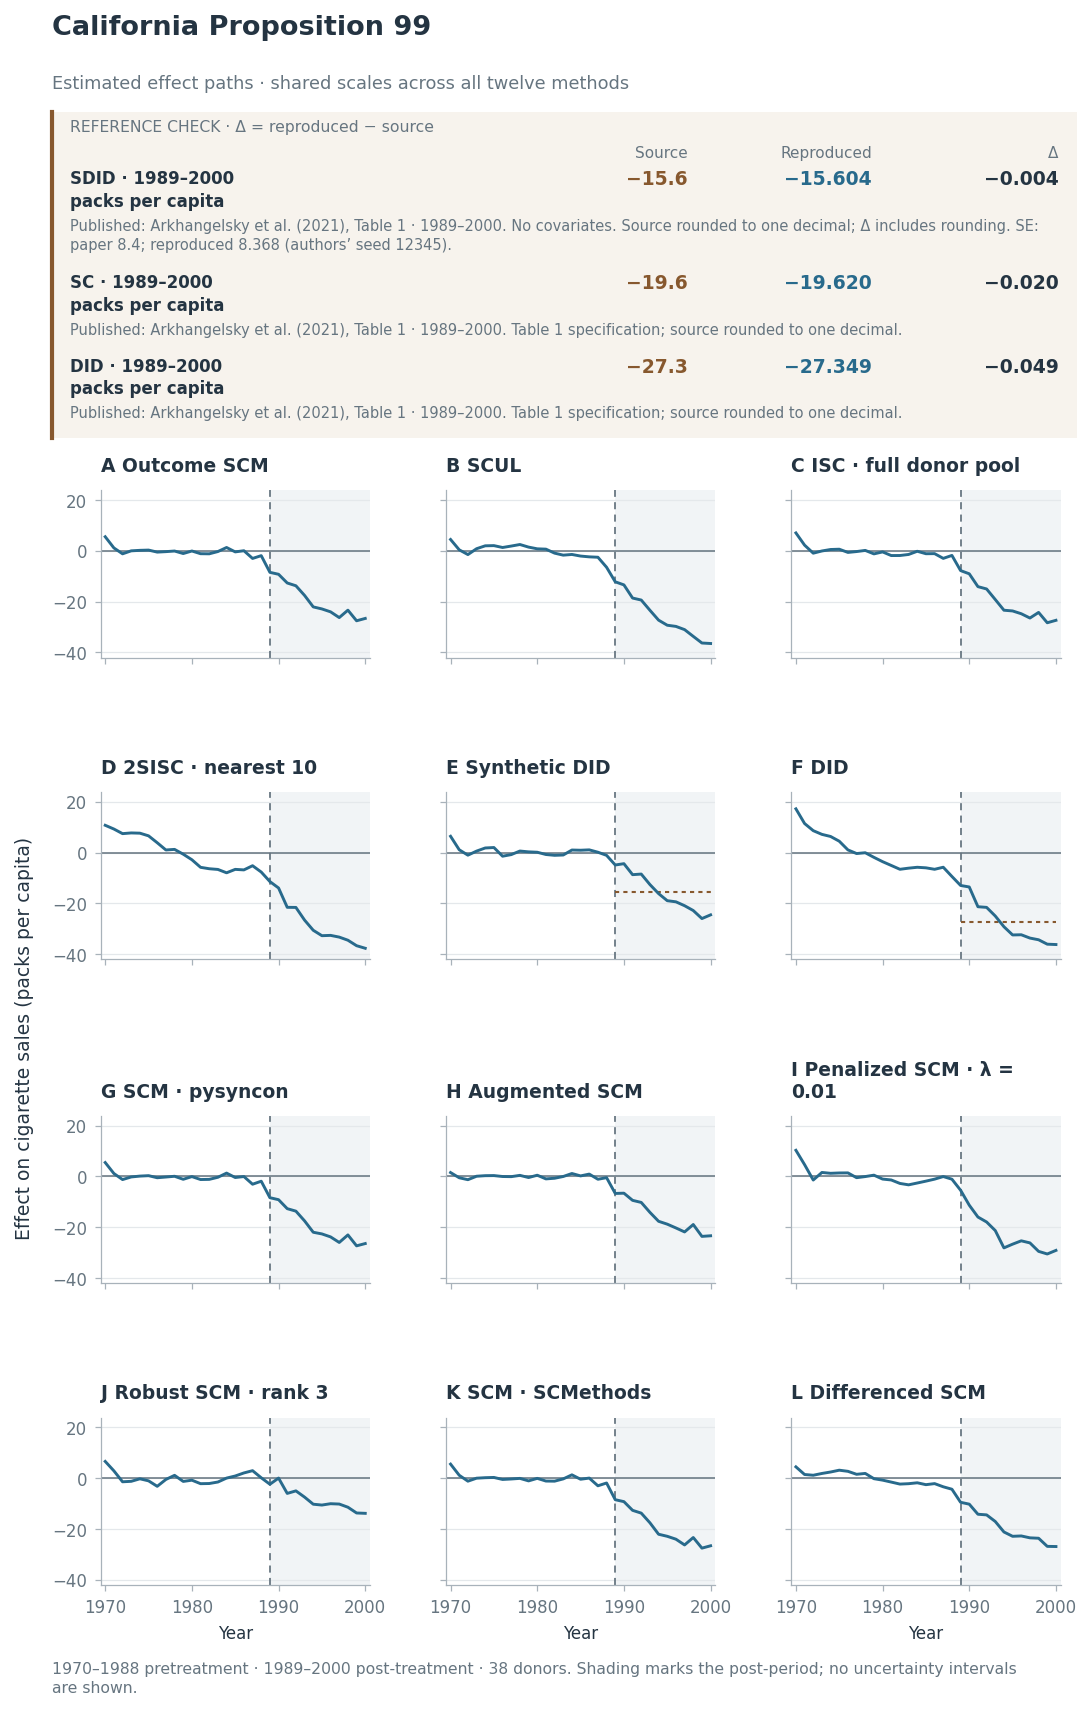

In [6]:
fig, axes = plot_effects(
    results, labels=display_labels,
    title=figure_details['case'],
    subtitle='Estimated effect paths · shared scales across all twelve methods',
    ylabel=figure_details['effect'], xlabel='Year',
    references=references,
    note=figure_details['periods'] + '. Shading marks the post-period; no uncertainty intervals are shown.',
)
effects_files = export_figure(fig, 'effects')
plt.show()

## Pretreatment validation and specification selection

These are **new analyses of the academic data**, separate from the paper
replications above. We compare methods and three prespecified 2SISC donor
counts on common withheld pretreatment blocks. Every actual post-treatment
row is excluded from validation. Held-out treated outcomes are masked
during fitting; contemporaneous donor outcomes remain available.

SCUL keeps its original internal rolling windows, so the outer training
sample must be long enough to contain them. Short panels consequently
offer only a few validation folds: this is a transparent illustration,
not strong evidence that the selected estimator is generally superior.
Every fit retains the estimator's full optimization and resampling settings.
SCUL's full-series admissibility screen sees the masked target series here.

Selection minimizes pooled held-out RMSE, then fits the winner on the
original panel. The selected score is optimistic after model selection;
no post-selection confidence interval or causal guarantee is implied.
Candidate choices and folds must be set before examining treatment effects.

/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/scul.py:211: RuntimeWarning: scul reference backend: Warning message:
In max(lambdapath[id1se], na.rm = TRUE) :
  no non-missing arguments to max; returning -Inf
  result = run_reference(


/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)


/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)


,rank,validation_rmse,mae,bias,n_predictions,n_folds
model,,,,,,
SDID,1,2.192458,2.144290,-2.144290,2,2
ISC,2,4.393778,4.094236,-4.094236,2,2
Outcome SCM,3,5.162860,4.879144,-4.879144,2,2
2SISC k=10,4,7.232317,7.072934,-7.072934,2,2
SCUL,5,8.383311,8.257643,-8.257643,2,2
DID,6,8.410669,8.250289,-8.250289,2,2
2SISC k=3,7,8.526076,8.060827,-8.060827,2,2
2SISC k=5,8,11.320766,10.735364,-10.735364,2,2


,model,fold,training_end,validation_start,validation_end,validation_rmse
0,Outcome SCM,0,1986,1987,1987,6.567064
1,Outcome SCM,1,1987,1988,1988,3.191224
2,SCUL,0,1986,1987,1987,6.811530
3,SCUL,1,1987,1988,1988,9.703755
4,ISC,0,1986,1987,1987,5.688763
5,ISC,1,1987,1988,1988,2.499710
6,SDID,0,1986,1987,1987,1.687238
7,SDID,1,1987,1988,1988,2.601341
8,DID,0,1986,1987,1987,6.615635
9,DID,1,1987,1988,1988,9.884943


Selected by pretreatment validation: SDID
Full-panel selected ATT: -15.6038


**Local figure exports** (relative to the notebook directory): `figures/california/california-validation.pdf` · `figures/california/california-validation.svg` · `figures/california/california-validation.png`

**Literature source:** [Arkhangelsky et al. (2021), Table 1 · 1989–2000](https://arxiv.org/pdf/1812.09970v4#page=8)

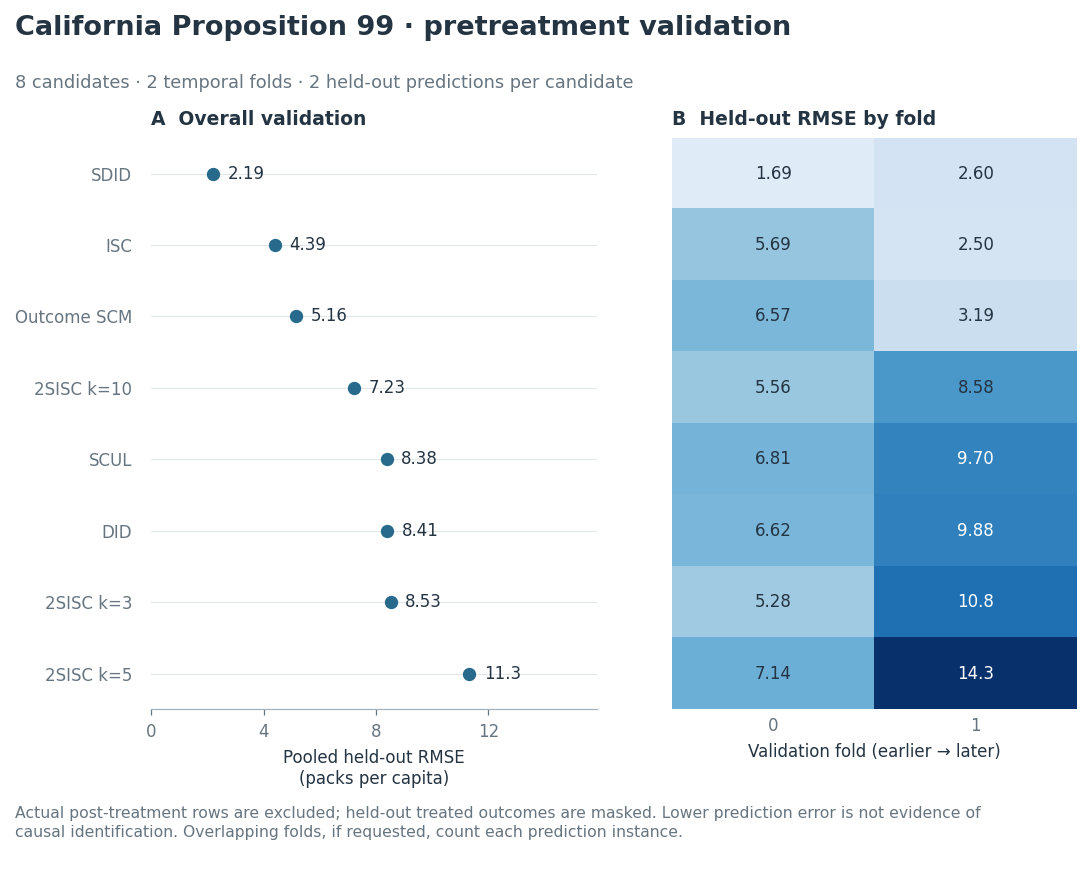

In [7]:
candidates = {
    'Outcome SCM': SyntheticControl,
    'SCUL': partial(SCUL, initial_window=initial, horizon=horizon),
    'ISC': IndividualSC,
    'SDID': SyntheticDID,
    'DID': DifferenceInDifferences,
    **{f'2SISC k={k}': partial(TwoStageIndividualSC, n_neighbors=k)
       for k in (3, 5, 10)},
}
validation_start = max(panel.n_pre // 2, initial + horizon)
validation_horizon = max(1, (panel.n_pre - validation_start) // 3)
selection = select_estimator(
    panel, candidates, initial_window=validation_start,
    horizon=validation_horizon,
)
validation = selection.validation
display(validation.summary)
display(validation.scores[['model', 'fold', 'training_end', 'validation_start',
                           'validation_end', 'validation_rmse']])
print(f'Selected by pretreatment validation: {selection.selected_name}')
print(f'Full-panel selected ATT: {selection.estimate.att:.6g}')
validation.summary.to_csv(figure_dir / f'{name}-validation-summary.csv')
validation.scores.to_csv(figure_dir / f'{name}-validation-folds.csv', index=False)
validation.predictions.to_csv(figure_dir / f'{name}-validation-predictions.csv', index=False)
fig, axes = plot_backtest(
    validation, title=figure_details['case'] + ' · pretreatment validation',
    units=figure_details['units'],
)
validation_files = export_figure(fig, 'validation')
plt.show()

## Dependence on donor eligibility

Remove **every eligible donor in turn** and completely refit three distinct
estimator families: outcome SCM, the authors' two-stage ISC specification,
and SDID. 2SISC repeats nearest-neighbor screening after each exclusion.
This includes donors whose baseline weight was zero; no old weights are
simply renormalized. The API accepts the other supported methods and
named donor groups using the same protocol.

The figure shows the baseline, every refitted ATT, and the largest absolute
change. Scenario ranges are **not confidence intervals**. Neither a stable
result nor a sign reversal establishes whether a donor is causally valid.
These diagnostics should inform the study design, not selection of a
donor pool that produces a preferred effect.

/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)
/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)


/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)
/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)


/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)
/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)
/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._e

/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)
/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)


/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)
/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)
/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._e

/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)
/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)


... (9 outputs left out)

/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)
/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)
/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:165: RuntimeWarning: SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata
  return self._e

,baseline_att,min_att,max_att,max_abs_change,worst_scenario,n_scenarios
model,,,,,,
Outcome SCM,-19.513667,-20.513575,-17.968219,1.545448,omit:Montana,38
2SISC k=10,-27.726675,-30.143218,-25.072518,2.654157,omit:West Virginia,38
SDID,-15.603828,-17.057786,-14.983059,1.453958,omit:Nevada,38


**Local figure exports** (relative to the notebook directory): `figures/california/california-donor-sensitivity.pdf` · `figures/california/california-donor-sensitivity.svg` · `figures/california/california-donor-sensitivity.png`

**Literature source:** [Arkhangelsky et al. (2021), Table 1 · 1989–2000](https://arxiv.org/pdf/1812.09970v4#page=8)

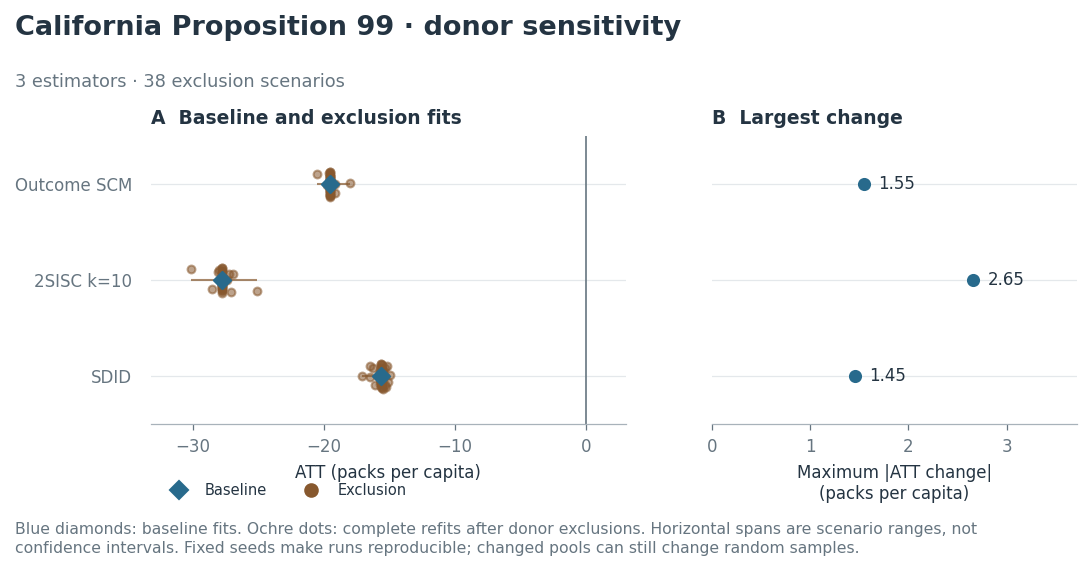

In [8]:
sensitivity = donor_sensitivity(panel, {
    'Outcome SCM': SyntheticControl,
    '2SISC k=10': partial(TwoStageIndividualSC, n_neighbors=10),
    'SDID': SyntheticDID,
})
display(sensitivity.summary)
sensitivity.table.to_csv(figure_dir / f'{name}-donor-sensitivity.csv', index=False)
sensitivity.summary.to_csv(figure_dir / f'{name}-donor-sensitivity-summary.csv')
fig, axes = plot_donor_sensitivity(
    sensitivity, title=figure_details['case'] + ' · donor sensitivity',
    units=figure_details['units'],
)
sensitivity_files = export_figure(fig, 'donor-sensitivity')
plt.show()

## SDID placebo inference and numerical convergence

The original synthdid placebo variance estimator refits donor and time
weights in each of 200 resamples. The seed is fixed. These standard errors
apply to SDID alone; they are not intervals for the other methods.
The bootstrap and jackknife are undefined with only one treated unit.
California uses the authors' exact R sampling plan (seed 12345),
reproducing the paper's standard error 8.4 at its printed precision.
The other examples use NumPy seed 0 for reproducible new applications.

The authors' 10,000-iteration cap can stop some draws before their
objective-decrease criterion is met. We retain that reference result,
then repeat **the identical 200 resamples** with up to 1,000,000 final-stage
iterations and require every resampled weight fit to meet the original
criterion. Penalties, tolerance, sparsification and starting weights
are unchanged. The larger cap is a numerical extension of the reference
software, not its exact finite-iteration replication.

The table compares both standard errors and capped-draw counts. The
original-cap SDID point estimate remains fixed for this comparison;
the strict check applies to resampled weight fits. Meeting the original
objective-decrease rule is not a global optimality certificate; dual
gaps and draw-level diagnostics are exported for inspection. Reference-cap
warnings remain visible; an unresolved extended fit stops the notebook.

In [9]:
if paper_uncertainty is not None:
    np.testing.assert_allclose(results['Synthetic DID'].att, reference.att, atol=1e-12)
    reference_uncertainty = paper_uncertainty
else:
    reference_uncertainty = SyntheticDID().inference(
        panel, method='placebo', replications=200, random_state=0,
        estimate=results['Synthetic DID'],
    )
uncertainty = SyntheticDID().inference(
    panel, method='placebo', replications=200,
    estimate=results['Synthetic DID'],
    resamples=reference_uncertainty.resamples,
    max_iter=1_000_000, require_convergence=True,
)
np.testing.assert_array_equal(uncertainty.resamples, reference_uncertainty.resamples)
assert uncertainty.metadata['capped_draws'] == 0
budget_comparison = pd.DataFrame([
    {
        'Run': label,
        'Final-stage iteration cap': fit.metadata['max_iter'],
        'Capped draws': fit.metadata['capped_draws'],
        'Placebo standard error': fit.standard_error,
        'SE change from reference cap': fit.standard_error - reference_uncertainty.standard_error,
        'Largest absolute draw change': np.max(np.abs(fit.draws - reference_uncertainty.draws)),
    }
    for label, fit in [('Reference cap', reference_uncertainty), ('Extended cap', uncertainty)]
]).set_index('Run')
display(budget_comparison)
budget_comparison.to_csv(figure_dir / f'{name}-sdid-budget-comparison.csv')
convergence = pd.concat({
    label: pd.json_normalize(fit.metadata['solver_diagnostics'])
    for label, fit in [('Reference cap', reference_uncertainty), ('Extended cap', uncertainty)]
}, names=['Run', 'Draw']).reset_index()
convergence.to_csv(figure_dir / f'{name}-sdid-convergence.csv', index=False)
inference = pd.Series({
    'SDID ATT': results['Synthetic DID'].att,
    'Placebo standard error': uncertainty.standard_error,
    '95% normal interval': uncertainty.confidence_interval(),
    'Replications': 200,
    'Final-stage iteration cap': uncertainty.metadata['max_iter'],
    'Capped resample fits': uncertainty.metadata['capped_draws'],
}, name='SDID inference')
display(inference)
inference.to_csv(figure_dir / f'{name}-sdid-inference.csv')
np.savetxt(figure_dir / f'{name}-sdid-resamples.csv', uncertainty.resamples, delimiter=',', fmt='%d')
np.savetxt(figure_dir / f'{name}-sdid-draws.csv', uncertainty.draws, delimiter=',')
np.savetxt(figure_dir / f'{name}-sdid-reference-draws.csv', reference_uncertainty.draws, delimiter=',')

,Final-stage iteration cap,Capped draws,Placebo standard error,SE change from reference cap,Largest absolute draw change
Run,,,,,
Reference cap,10000,109,8.367993,0.000000,0.000000
Extended cap,1000000,0,8.368944,0.000951,0.037566


SDID ATT                                                   -15.603828
Placebo standard error                                       8.368944
95% normal interval          (-32.006657421215124, 0.799001675747423)
Replications                                                      200
Final-stage iteration cap                                     1000000
Capped resample fits                                                0
Name: SDID inference, dtype: object

## Inspect the donor coefficients

These are the fifteen donors with the largest absolute coefficient in
any method, not an exhaustive donor list. The coefficients are not
renormalized. SCUL and some augmented/robust estimates can have negative
weights or weight sums different from one. Intercepts and SDID time
weights are separate components; this table does not represent them.

In [10]:
weights = pd.concat({label: fit.weights for label, fit in results.items()}, axis=1)
weights.loc[weights.abs().max(axis=1).sort_values(ascending=False).index].head(15).round(4)

,Outcome SCM,SCUL,ISC (full donor pool),2SISC (nearest 10),Synthetic DID,DID,pysyncon SCM,Augmented SCM,Penalized SCM (0.01),"Robust SCM (rank 3, ridge 0.1)",SyntheticControlMethods SCM,Differenced SCM
Utah,0.3939,0.0000,0.3335,0.0000,0.0415,0.0263,0.3970,0.3702,0.0000,0.0307,0.3939,0.1640
Montana,0.2318,0.2085,0.1388,0.0954,0.0451,0.0263,0.2101,0.2484,0.3753,0.0211,0.2318,0.2460
Connecticut,0.1091,0.0000,0.0554,0.0901,0.0783,0.0263,0.1068,0.1512,0.1010,0.0590,0.1091,0.2882
Idaho,0.0000,0.0000,0.0440,0.0882,0.0315,0.0263,0.0000,-0.0191,0.2881,0.0404,0.0000,0.0000
Nevada,0.2049,0.1558,0.1462,0.0000,0.1245,0.0263,0.2056,0.2020,0.0817,0.1194,0.2049,0.1691
New Mexico,0.0000,0.0000,0.0572,0.0000,0.0406,0.0263,0.0000,-0.0004,0.1539,0.0510,0.0000,0.0000
Illinois,0.0000,0.1428,0.0258,0.0000,0.0534,0.0263,0.0000,0.0502,0.0000,0.0836,0.0000,0.0000
Colorado,0.0148,0.0365,0.0721,0.1308,0.0575,0.0263,0.0358,0.0328,0.0000,0.0635,0.0148,0.1326
Kansas,0.0000,0.0000,0.0018,0.1110,0.0216,0.0263,0.0000,0.0444,0.0000,0.0417,0.0000,0.0000
West Virginia,0.0000,0.0000,0.0000,0.1076,0.0336,0.0263,0.0000,0.0270,0.0000,-0.0593,0.0000,0.0000


## Interpretation, exports and reproducibility

Negative effects mean the observed outcome is below its estimated
untreated path. These are point estimates under different restrictions,
tuning choices and identifying assumptions. They are not an uncertainty
distribution. The historical reference check is distinct from the new
comparison specifications and their stated tuning choices.

Each figure is exported at **7.2 inches wide** in three formats: PDF with
embedded fonts, SVG with editable text, and 300 dpi PNG. The local paths
are printed beside each embedded figure. Generated figures, CSV summaries,
and diagnostic files stay outside version control; rerunning the notebook
recreates them. Use vector formats for manuscripts and adjust figure size, labels
and captions through the plotting API before exporting to a journal's
requirements. Nothing depends on system fonts or an external TeX install.

`pysynth.placebo_test` provides in-space RMSPE-ratio diagnostics and a
rank statistic. The treated and placebo fits have different donor-pool sizes,
so exchangeability alone does not make this an exact randomization test.
It is not synthdid's placebo
variance estimator. The original SCUL scanner-data and ISC/costofcare
survey studies are not reproduced here. Re-run from a fresh kernel to
reproduce the source checks, estimates and figures together.